# 第03章 习题3.1：Euler方法与RK4——教师参考验证

本文件专门核验习题3.1-1至3.1-4的答案，**不属于正文课堂实验Notebook**。

初值问题为
$$y'(t)=-2y(t)+2t+1,\quad y(0)=1,$$
解析解为 $y(t)=t+e^{-2t}$。分别实现向前Euler、向后Euler与经典RK4，使用双精度计算。向后Euler在**本题**具有闭式隐式更新，无需Newton迭代；其他非线性问题不能沿用这个公式。


In [2]:
import sys
import math
import platform
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

out_dir = Path("images")
out_dir.mkdir(exist_ok=True)

def f(t, y):
    return -2.0*y + 2.0*t + 1.0

def y_exact(t):
    return t + math.exp(-2.0*t)

def forward_euler(t, y, h):
    return y + h*f(t, y)

def backward_euler(t, y, h):
    # Solve u - y - h*(-2*u+2*(t+h)+1) = 0 exactly.
    next_t = t + h
    return (y + h*(2.0*next_t + 1.0))/(1.0 + 2.0*h)

def rk4(t, y, h):
    k1 = f(t, y)
    k2 = f(t + h/2, y + h*k1/2)
    k3 = f(t + h/2, y + h*k2/2)
    k4 = f(t + h, y + h*k3)
    return y + h*(k1 + 2*k2 + 2*k3 + k4)/6

steps = {
    "Forward Euler": forward_euler,
    "Backward Euler": backward_euler,
    "Classical RK4": rk4,
}
rhs_evals_per_step = {"Forward Euler": 1, "Backward Euler": 0, "Classical RK4": 4}

def solve(name, N, T=2.0):
    if isinstance(N, bool) or not isinstance(N, int) or N < 1:
        raise ValueError("N must be a positive integer")
    if T <= 0:
        raise ValueError("T must be positive")
    h = T/N
    times = [n*h for n in range(N+1)]
    values = [1.0]
    residuals = []
    step = steps[name]
    for n in range(N):
        y_next = step(times[n], values[-1], h)
        if name == "Backward Euler":
            residuals.append(y_next - values[-1] - h*f(times[n+1], y_next))
        values.append(y_next)
    return times, values, residuals

def amp(name, z):
    if name == "Forward Euler":
        return 1+z
    if name == "Backward Euler":
        return 1/(1-z)
    return 1+z+z**2/2+z**3/6+z**4/24

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("OS:", platform.system(), platform.machine())
print("No random inputs or seeds are used.")


Python: 3.10.13
NumPy: 2.2.6
Matplotlib: 3.9.0
OS: Darwin arm64
No random inputs or seeds are used.


## 习题3.1-1：解析解与一步手算核验

In [3]:
h = 0.5
y0, t0 = 1.0, 0.0
k1 = f(t0, y0)
k2 = f(t0+h/2, y0+h*k1/2)
k3 = f(t0+h/2, y0+h*k2/2)
k4 = f(t0+h, y0+h*k3)
print(f"RK4 stages: k1={k1:.6f}, k2={k2:.6f}, k3={k3:.6f}, k4={k4:.6f}")
for name in steps:
    y1 = solve(name, 1, T=h)[1][-1]
    print(f"{name:15s} y(0.5)={y1:.12f}, signed error={y1-y_exact(h):+.12f}")
print(f"Exact             y(0.5)={y_exact(h):.12f}")
assert abs(y_exact(0) - 1) < 1e-14
assert abs(forward_euler(0, 1, .5)-.5)<1e-14
assert abs(backward_euler(0, 1, .5)-1.)<1e-14
assert abs(rk4(0, 1, .5)-.875)<1e-14
assert (k1,k2,k3,k4)==(-1.0,0.0,-0.5,0.5)


RK4 stages: k1=-1.000000, k2=0.000000, k3=-0.500000, k4=0.500000
Forward Euler   y(0.5)=0.500000000000, signed error=-0.367879441171
Backward Euler  y(0.5)=1.000000000000, signed error=+0.132120558829
Classical RK4   y(0.5)=0.875000000000, signed error=+0.007120558829
Exact             y(0.5)=0.867879441171


## 习题3.1-2：步长加密与观测收敛阶

主区间 $T=2$，步数 $N=4,8,16,32,64$。另用解析递推
$$
y_N^{\mathrm{FE}}=T+(1-2h)^N,\quad
y_N^{\mathrm{BE}}=T+(1+2h)^{-N},\quad
y_N^{\mathrm{RK4}}=T+R_{\mathrm{RK4}}(-2h)^N
$$
交叉检查。


In [4]:
NS = [4,8,16,32,64]
reference = y_exact(2.0)
results = {}
print(f"Reference y(2) = {reference:.12f}")
print(" N      h         Forward Euler     Backward Euler      Classical RK4")
for N in NS:
    h = 2.0/N
    results[N] = {}
    row = []
    for name in steps:
        _, ys, _ = solve(name, N)
        yN = ys[-1]
        err = abs(yN-reference)
        independent = 2 + amp(name, -2*h)**N
        assert abs(yN-independent) < 2e-11, (name, N, yN, independent)
        results[N][name] = (yN, err)
        row.append(f"{yN:.12f}")
    print(f"{N:2d}  {h:.7f}  " + "  ".join(row))
print("\n N            FE error          BE error         RK4 error")
for N in NS:
    e = [results[N][name][1] for name in steps]
    print(f"{N:2d}       {e[0]:.12e}  {e[1]:.12e}  {e[2]:.12e}")
print("\n N -> 2N       FE order      BE order      RK4 order")
for N in NS[:-1]:
    p = [math.log2(results[N][name][1]/results[2*N][name][1]) for name in steps]
    print(f"{N:2d} -> {2*N:2d}      {p[0]:.6f}       {p[1]:.6f}       {p[2]:.6f}")
print("Recurrence cross-checks passed.")


Reference y(2) = 2.018315638889
 N      h         Forward Euler     Backward Euler      Classical RK4
 4  0.5000000  2.000000000000  2.062500000000  2.019775390625
 8  0.2500000  2.003906250000  2.039018442311  2.018373740285
16  0.1250000  2.010022595758  2.028147497671  2.018318578143
32  0.0625000  2.013939837038  2.023073808382  2.018315804332
64  0.0312500  2.016075396351  2.020651325015  2.018315648703

 N            FE error          BE error         RK4 error
 4       1.831563888873e-02  4.418436111127e-02  1.459751736266e-03
 8       1.440938888873e-02  2.070280342189e-02  5.810139581497e-05
16       8.293043131116e-03  9.831858782331e-03  2.939253946010e-06
32       4.375801851051e-03  4.758169493400e-03  1.654430898945e-07
64       2.240242537781e-03  2.335686126399e-03  9.814253854046e-09

 N -> 2N       FE order      BE order      RK4 order
 4 ->  8      0.346067       1.093710       4.651006
 8 -> 16      0.797036       1.074290       4.305051
16 -> 32      0.922354      

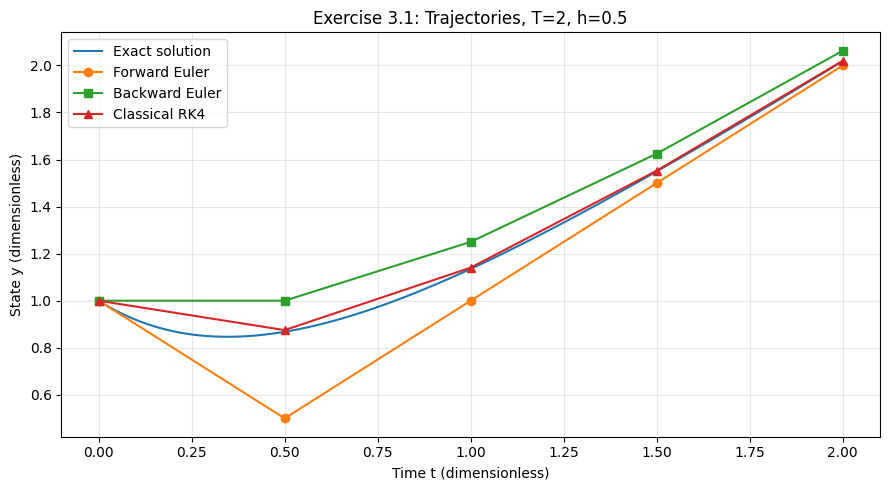

In [4]:
dense = np.linspace(0, 2, 501)
plt.figure(figsize=(9,5))
plt.plot(dense, [y_exact(t) for t in dense], label="Exact solution")
for name, marker in zip(steps, ("o", "s", "^")):
    t, y, _ = solve(name, 4, T=2.0)
    plt.plot(t, y, marker=marker, label=name)
plt.xlabel("Time t (dimensionless)")
plt.ylabel("State y (dimensionless)")
plt.title("Exercise 3.1: Trajectories, T=2, h=0.5")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(out_dir/"ex_3_1_trajectory.png", dpi=160)
plt.show()


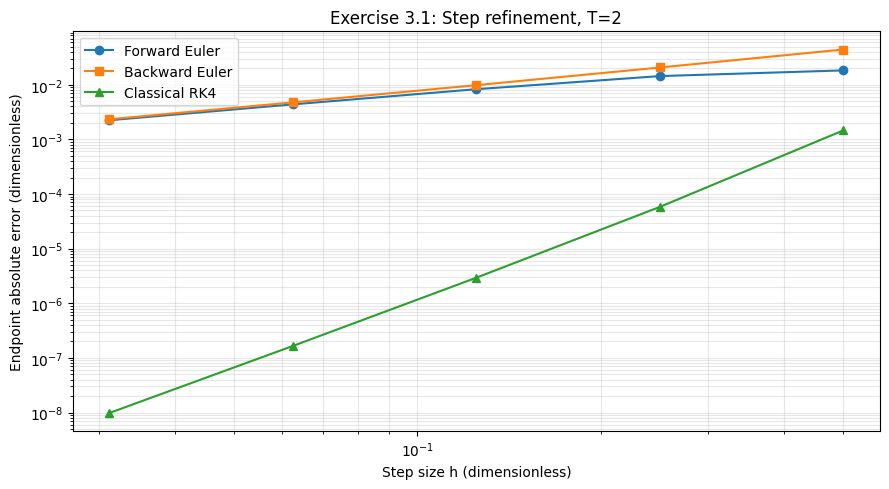

In [5]:
plt.figure(figsize=(9,5))
for name, marker in zip(steps, ("o", "s", "^")):
    plt.loglog([2/N for N in NS], [results[N][name][1] for N in NS],
               marker=marker, label=name)
plt.xlabel("Step size h (dimensionless)")
plt.ylabel("Endpoint absolute error (dimensionless)")
plt.title("Exercise 3.1: Step refinement, T=2")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir/"ex_3_1_convergence.png", dpi=160)
plt.show()


## 习题3.1-3：非自治方程的稳定性辨析

通过 $w=y-t$ 得到 $w'=-2w$、$w(0)=1$。令 $h=1.25$、$T=5$，比较 $y_n=t_n+R(-2h)^n$ 与精确解。


In [6]:
T_STAB = 5.0
N_STAB = 4
print("Amplification factors at z=-2.5:")
for name in steps:
    factor = amp(name, -2.5)
    print(f"{name:15s}: R(-2.5)={factor:+.10f} |R|={abs(factor):.10f}")
print("\n  t         Exact           Forward Euler     Backward Euler     Classical RK4")
data_stab = {name: solve(name, N_STAB, T_STAB)[1] for name in steps}
ts = solve("Forward Euler", N_STAB, T_STAB)[0]
for i, t in enumerate(ts):
    ys = [data_stab[name][i] for name in steps]
    for name, value in zip(steps, ys):
        assert abs(value-(t+amp(name,-2.5)**i)) < 3e-13
    print(f"{t:5.2f}  {y_exact(t):.12f}  " + "  ".join(f"{y:.12f}" for y in ys))
print("\nEndpoint absolute errors:")
for name in steps:
    print(f"{name:15s}: {abs(data_stab[name][-1]-y_exact(5)):.12f}")
print(f"Exact y(5)={y_exact(5):.12f}")


Amplification factors at z=-2.5:
Forward Euler  : R(-2.5)=-1.5000000000 |R|=1.5000000000
Backward Euler : R(-2.5)=+0.2857142857 |R|=0.2857142857
Classical RK4  : R(-2.5)=+0.6484375000 |R|=0.6484375000

  t         Exact           Forward Euler     Backward Euler     Classical RK4
 0.00  1.000000000000  1.000000000000  1.000000000000  1.000000000000
 1.25  1.332084998624  -0.250000000000  1.535714285714  1.898437500000
 2.50  2.506737946999  4.750000000000  2.581632653061  2.920471191406
 3.75  3.750553084370  0.375000000000  3.773323615160  4.022649288177
 5.00  5.000045399930  10.062500000000  5.006663890046  5.176796022803

Endpoint absolute errors:
Forward Euler  : 5.062454600070
Backward Euler : 0.006618490116
Classical RK4  : 0.176750622873
Exact y(5)=5.000045399930


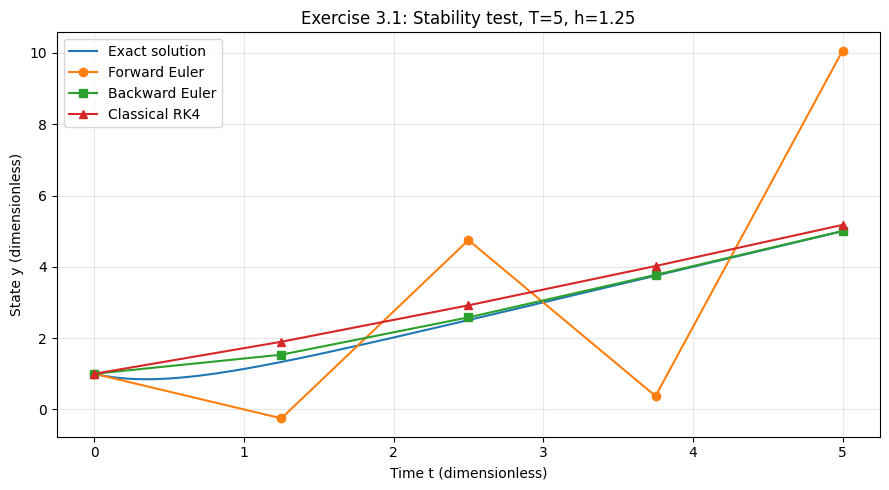

In [7]:
dense = np.linspace(0, 5, 601)
plt.figure(figsize=(9,5))
plt.plot(dense, [y_exact(t) for t in dense], label="Exact solution")
for name, marker in zip(steps, ("o", "s", "^")):
    plt.plot(ts, data_stab[name], marker=marker, label=name)
plt.xlabel("Time t (dimensionless)")
plt.ylabel("State y (dimensionless)")
plt.title("Exercise 3.1: Stability test, T=5, h=1.25")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(out_dir/"ex_3_1_stability.png", dpi=160)
plt.show()


## 习题3.1-4：精度目标、隐式残差与成本

误差目标为 $10^{-4}$，只搜索 $N=4,8,16,\ldots$。向后Euler对当前模型采取闭式求根，而非Newton迭代。报告每步代数残差的最大绝对值。


In [8]:
target = 1e-4
passing = {}
for name in steps:
    for k in range(2,18):
        N = 2**k
        t, y, r = solve(name,N,T=2.0)
        err = abs(y[-1]-y_exact(2.0))
        if err <= target:
            passing[name] = (N,2/N,err)
            report = f"{name:15s}: N={N:5d}, h={2/N:.11f}, error={err:.12e}"
            if name == "Backward Euler":
                max_residual = max(map(abs,r))
                report += f", max algebraic residual={max_residual:.12e}"
                assert max_residual < 1e-10
            else:
                report += f", RHS evals={N*rhs_evals_per_step[name]}"
            print(report)
            break
    else:
        raise AssertionError(f"Did not reach tolerance: {name}")
assert passing["Forward Euler"][0] == 2048
assert passing["Backward Euler"][0] == 2048
assert passing["Classical RK4"][0] == 8
print("Forward Euler / RK4 RHS cost ratio: 2048 / 32 = 64")
print("All tests passed; teacher notebook was actually executed.")


Forward Euler  : N= 2048, h=0.00097656250, error=7.149883982116e-05, RHS evals=2048
Backward Euler : N= 2048, h=0.00097656250, error=7.159199802542e-05, max algebraic residual=2.211772431870e-16
Classical RK4  : N=    8, h=0.25000000000, error=5.810139581497e-05, RHS evals=32
Forward Euler / RK4 RHS cost ratio: 2048 / 32 = 64
All tests passed; teacher notebook was actually executed.
